First five rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


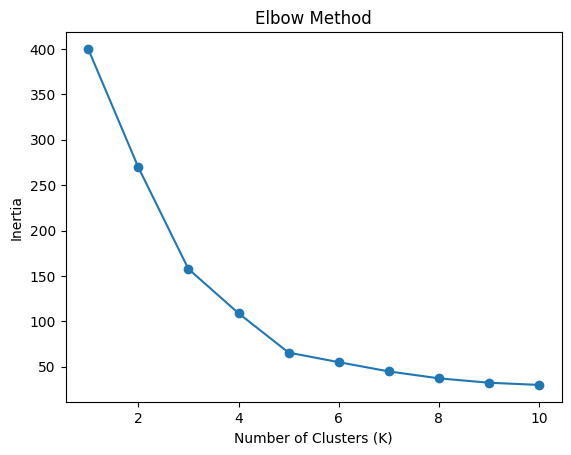


Cluster assignments:
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4

Cluster centroids:
   Annual Income (k$)  Spending Score (1-100)
0               55.30                   49.52
1               86.54                   82.13
2               25.73                   79.36
3               88.20                   17.11
4               26.30                   20.91


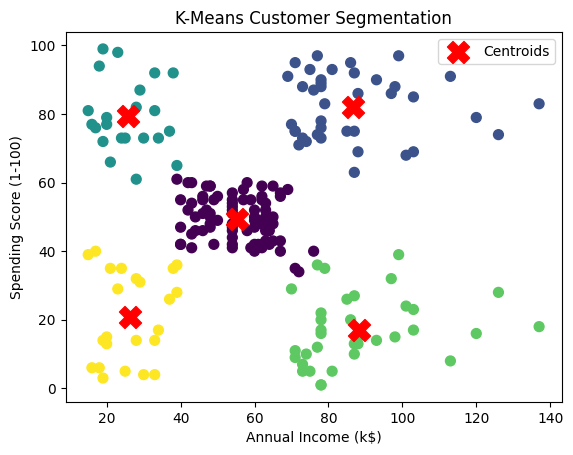


Number of clusters: 5
Silhouette Score: 0.555

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [1]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Step 2: Load dataset
df = pd.read_csv("/content/Mall_Customers.csv")
print("First five rows:")
print(df.head())

# Step 3: Select features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Step 4: Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Find optimal K using the Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

# Step 6: Apply K-Means (commonly use K = 5 for this dataset)
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Step 7: Display cluster assignments
print("\nCluster assignments:")
print(df[["Annual Income (k$)",
          "Spending Score (1-100)", "Cluster"]].head())

# Step 8: Display centroids in original units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
print("\nCluster centroids:")
print(pd.DataFrame(
    centroids,
    columns=["Annual Income (k$)", "Spending Score (1-100)"]
).round(2))

# Step 9: Visualize clusters and centroids
plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=50
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    color="red",
    s=250,
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Customer Segmentation")
plt.legend()
plt.show()

# Step 10: Evaluate clustering
score = silhouette_score(X_scaled, df["Cluster"])
print("\nNumber of clusters:", k)
print("Silhouette Score:", round(score, 3))

print("\nNumber of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())